=== Table Data Comparison Tool (Percentage View) ===


Generating percentage comparison chart...

=== Performance Analysis (Percentage View) ===
Code     Auto Total   Syn Total    Auto %     Difference  
-----------------------------------------------------------------
VA       1,012,473    1,423,165    71.1      % -410,692    
RED      1,044,604    1,740,219    60.0      % -695,615    
GEMV     2,422,903    2,419,373    100.1     % 3,530       
HST-S    2,115,703    3,164,934    66.8      % -1,049,231  
SEL      142,657      5,895,648    2.4       % -5,752,991  
TS       5,277,856    5,929,253    89.0      % -651,397    
MLP      5,772,954    6,262,123    92.2      % -489,169    

Chart saved to: synchronous.png

=== Component Breakdown (Percentage) ===

VA:
  Auto - Total: 1,012,473 (71.1% of Syn)
  Syn  - Total: 1,423,165 (100.0%)
  Auto is 71.1% the size of Syn

RED:
  Auto - Total: 1,044,604 (60.0% of Syn)
  Syn  - Total: 1,740,219 (100.0%)
  Auto is 60.0% the size of Syn

GEMV:
 

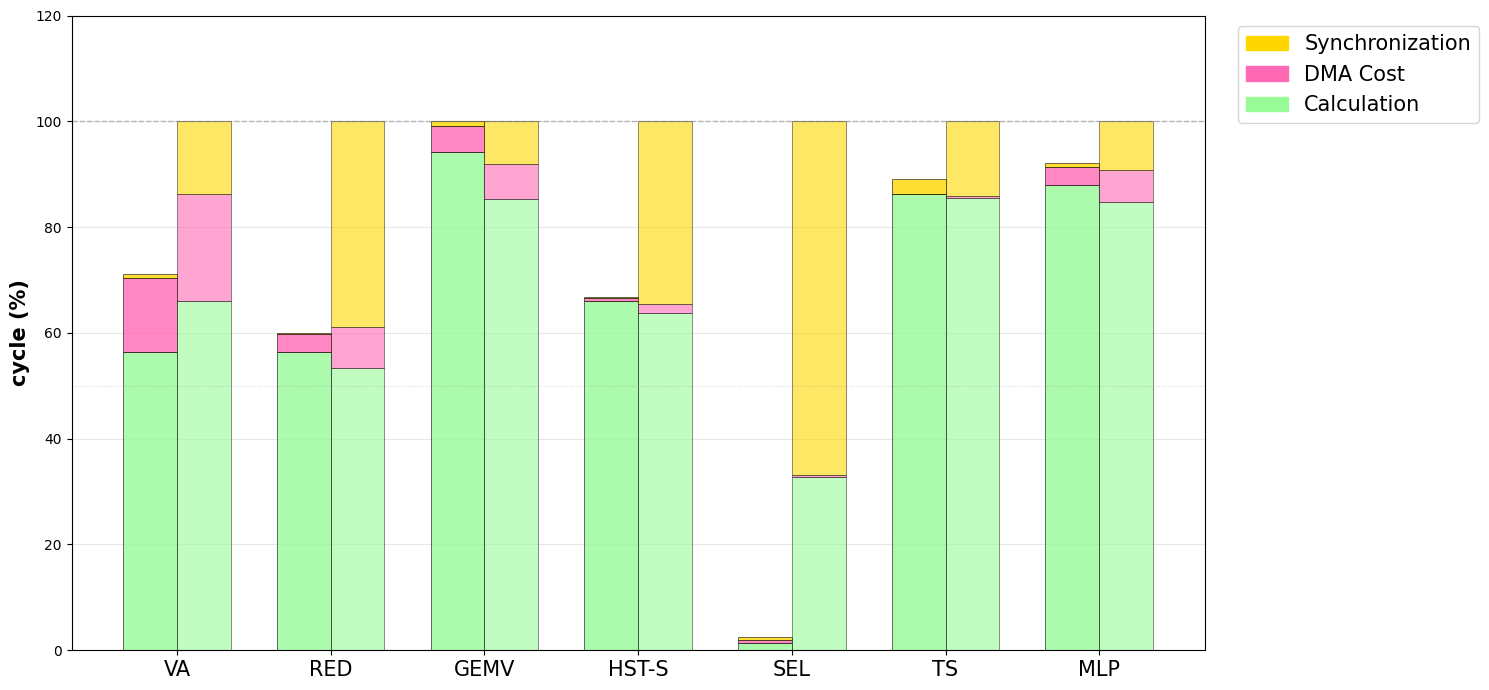

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
import matplotlib.patches as mpatches

# Set font for better display
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

def parse_table_data(data_text):
    """Parse table data from text"""
    lines = data_text.strip().split('\n')
    parsed_data = []
    
    for line in lines:
        parts = line.split('\t')
        if len(parts) >= 4:
            code = parts[0].strip()
            total_cycle = int(parts[1]) if parts[1].strip() else 0
            dma_cost = int(parts[2]) if parts[2].strip() else 0
            dma_times = int(parts[3]) if parts[3].strip() else 0
            
            # Calculate barrier sum (from column 5 onwards)
            barrier_sum = 0
            for i in range(4, len(parts)):
                if parts[i].strip():
                    barrier_sum += int(parts[i])
            
            # Calculate remaining part
            remaining = max(0, total_cycle - dma_cost - barrier_sum)
            
            parsed_data.append({
                'code': code,
                'total_cycle': total_cycle,
                'dma_cost': dma_cost,
                'dma_times': dma_times,
                'barrier_sum': barrier_sum,
                'remaining': remaining
            })
    
    return parsed_data

def create_comparison_chart_percentage(table1_data, table2_data, save_path=None):
    """Create comparison bar chart with percentage scaling"""
    # Convert to DataFrames
    df1 = pd.DataFrame(table1_data)
    df2 = pd.DataFrame(table2_data)
    
    # Find common codes
    common_codes = list(set(df1['code']) & set(df2['code']))
    
    if not common_codes:
        print("No common codes found between tables!")
        return None, None
    
    # Filter data for common codes and sort by total_cycle (ascending)
    df1_filtered = df1[df1['code'].isin(common_codes)].copy()
    df2_filtered = df2[df2['code'].isin(common_codes)].copy()
    
    # Sort by average total_cycle of both tables
    code_totals = {}
    for code in common_codes:
        total1 = df1_filtered[df1_filtered['code'] == code]['total_cycle'].iloc[0]
        total2 = df2_filtered[df2_filtered['code'] == code]['total_cycle'].iloc[0]
        code_totals[code] = (total1 + total2) / 2  # Average of both tables
    
    # Sort codes by average total_cycle (ascending)
    sorted_codes = sorted(common_codes, key=lambda x: code_totals[x])
    
    # Reorder dataframes according to sorted codes
    df1_filtered = df1_filtered.set_index('code').loc[sorted_codes]
    df2_filtered = df2_filtered.set_index('code').loc[sorted_codes]
    
    # Calculate percentage values for each code group
    def calculate_percentage_values(df_auto, df_syn):
        percentage_data = {}
        
        for code in sorted_codes:
            # Get absolute values
            auto_total = df_auto.loc[code, 'total_cycle']
            syn_total = df_syn.loc[code, 'total_cycle']
            
            auto_barrier = df_auto.loc[code, 'barrier_sum']
            auto_dma = df_auto.loc[code, 'dma_cost']
            auto_remaining = df_auto.loc[code, 'remaining']
            
            syn_barrier = df_syn.loc[code, 'barrier_sum']
            syn_dma = df_syn.loc[code, 'dma_cost']
            syn_remaining = df_syn.loc[code, 'remaining']
            
            # Syn is always 100%
            syn_total_pct = 100.0
            syn_barrier_pct = (syn_barrier / syn_total * 100) if syn_total > 0 else 0
            syn_dma_pct = (syn_dma / syn_total * 100) if syn_total > 0 else 0
            syn_remaining_pct = (syn_remaining / syn_total * 100) if syn_total > 0 else 0
            
            # Auto scaled relative to Syn
            auto_scale_factor = (auto_total / syn_total * 100) if syn_total > 0 else 0
            auto_total_pct = auto_scale_factor
            auto_barrier_pct = (auto_barrier / syn_total * 100) if syn_total > 0 else 0
            auto_dma_pct = (auto_dma / syn_total * 100) if syn_total > 0 else 0
            auto_remaining_pct = (auto_remaining / syn_total * 100) if syn_total > 0 else 0
            
            percentage_data[code] = {
                'auto_total': auto_total_pct,
                'auto_barrier': auto_barrier_pct,
                'auto_dma': auto_dma_pct,
                'auto_remaining': auto_remaining_pct,
                'syn_total': syn_total_pct,
                'syn_barrier': syn_barrier_pct,
                'syn_dma': syn_dma_pct,
                'syn_remaining': syn_remaining_pct,
                'auto_absolute': auto_total,
                'syn_absolute': syn_total
            }
        
        return percentage_data
    
    percentage_data = calculate_percentage_values(df1_filtered, df2_filtered)
    
    # Create figure and axis
    fig, ax = plt.subplots(figsize=(15, 7))
    
    # Set bar width and positions
    bar_width = 0.35
    x_pos = np.arange(len(sorted_codes))
    
    # Colors for different components
    colors = {
        'barrier': '#FFD700',    # Gold
        'dma': '#FF69B4',        # Hot Pink
        'remaining': '#98FB98'    # Pale Green
    }
    
    # Colors for table comparison
    table_colors = {
        'table1': '#FF6B6B',     # Red
        'table2': '#4ECDC4'      # Teal
    }
    
    # Extract data for plotting
    auto_remaining_pct = [percentage_data[code]['auto_remaining'] for code in sorted_codes]
    auto_dma_pct = [percentage_data[code]['auto_dma'] for code in sorted_codes]
    auto_barrier_pct = [percentage_data[code]['auto_barrier'] for code in sorted_codes]
    
    syn_remaining_pct = [percentage_data[code]['syn_remaining'] for code in sorted_codes]
    syn_dma_pct = [percentage_data[code]['syn_dma'] for code in sorted_codes]
    syn_barrier_pct = [percentage_data[code]['syn_barrier'] for code in sorted_codes]
    
    # Create stacked bars for Auto (Left side)
    bars1_remaining = ax.bar(x_pos - bar_width/2, auto_remaining_pct, 
                            bar_width, label='Auto - Other', 
                            color=colors['remaining'], alpha=0.8, edgecolor='black', linewidth=0.5)
    
    bars1_dma = ax.bar(x_pos - bar_width/2, auto_dma_pct, 
                       bar_width, bottom=auto_remaining_pct,
                       label='Auto - DMA Cost', 
                       color=colors['dma'], alpha=0.8, edgecolor='black', linewidth=0.5)
    
    bars1_barrier = ax.bar(x_pos - bar_width/2, auto_barrier_pct, 
                          bar_width, bottom=np.array(auto_remaining_pct) + np.array(auto_dma_pct),
                          label='Auto - Barrier Sum', 
                          color=colors['barrier'], alpha=0.8, edgecolor='black', linewidth=0.5)
    
    # Create stacked bars for Syn (Right side) - Always 100%
    bars2_remaining = ax.bar(x_pos + bar_width/2, syn_remaining_pct, 
                            bar_width, label='Syn - Other', 
                            color=colors['remaining'], alpha=0.6, edgecolor='black', linewidth=0.5)
    
    bars2_dma = ax.bar(x_pos + bar_width/2, syn_dma_pct, 
                       bar_width, bottom=syn_remaining_pct,
                       label='Syn - DMA Cost', 
                       color=colors['dma'], alpha=0.6, edgecolor='black', linewidth=0.5)
    
    bars2_barrier = ax.bar(x_pos + bar_width/2, syn_barrier_pct, 
                          bar_width, bottom=np.array(syn_remaining_pct) + np.array(syn_dma_pct),
                          label='Syn - Barrier Sum', 
                          color=colors['barrier'], alpha=0.6, edgecolor='black', linewidth=0.5)
    
    # 注释：移除了添加柱状图上方文字标签的代码段
    # 原来的代码在这里添加了百分比和绝对值标签，现在已删除
    
    # Customize the chart

    ax.set_ylabel('Cycle (%)', fontsize=15, fontweight='bold')

    ax.set_xticks(x_pos)
    ax.set_xticklabels(sorted_codes, fontsize=15)
    
    # 修改：将Y轴最大值从120改为100，去除额外的空间
    ax.set_ylim(0, 120)
    ax.set_ylabel('cycle (%)', fontsize=15, fontweight='bold')
    
    # Add horizontal reference lines
    ax.axhline(y=100, color='gray', linestyle='--', alpha=0.5, linewidth=1)
    ax.axhline(y=50, color='gray', linestyle=':', alpha=0.3, linewidth=0.8)
    
    # Create custom legend
    legend_elements = [
        mpatches.Patch(color=colors['barrier'], label='Synchronization'),
        mpatches.Patch(color=colors['dma'], label='DMA Cost'),
        mpatches.Patch(color=colors['remaining'], label='Calculation'),
    ]
    
    ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=15)
    
    # Add grid for better readability
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_axisbelow(True)
    
    # Adjust layout to prevent legend cutoff
    plt.tight_layout()
    
    # Print statistics
    print("\n=== Performance Analysis (Percentage View) ===")
    print(f"{'Code':<8} {'Auto Total':<12} {'Syn Total':<12} {'Auto %':<10} {'Difference':<12}")
    print("-" * 65)
    
    for code in sorted_codes:
        auto_abs = percentage_data[code]['auto_absolute']
        syn_abs = percentage_data[code]['syn_absolute']
        auto_pct = percentage_data[code]['auto_total']
        diff = auto_abs - syn_abs
        print(f"{code:<8} {auto_abs:<12,} {syn_abs:<12,} {auto_pct:<10.1f}% {diff:<12,}")
    
    # Save or show the plot
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
        print(f"\nChart saved to: {save_path}")
    else:
        plt.show()
    
    return fig, ax, sorted_codes

def read_csv_data(csv_file_path):
    """Read CSV file and convert to required format"""
    try:
        # Read CSV file
        df = pd.read_csv(csv_file_path)
       
        
        data = []
        for _, row in df.iterrows():
            code = str(row['code'])
            total_cycle = int(row['total_cycle']) if pd.notna(row['total_cycle']) else 0
            dma_cost = int(row['dma_cost']) if pd.notna(row['dma_cost']) else 0
            dma_times = int(row['dma_times']) if pd.notna(row['dma_times']) else 0
            
            # Calculate barrier sum (barrier_0 to barrier_9)
            barrier_sum = 0
            for i in range(10):  # barrier_0 to barrier_9
                col_name = f'barrier_{i}'
                if col_name in df.columns and pd.notna(row[col_name]):
                    barrier_sum += int(row[col_name])
            
            # Calculate remaining part
            remaining = max(0, total_cycle - dma_cost - barrier_sum)
            
            data.append({
                'code': code,
                'total_cycle': total_cycle,
                'dma_cost': dma_cost,
                'dma_times': dma_times,
                'barrier_sum': barrier_sum,
                'remaining': remaining
            })
        
        return data
    
    except Exception as e:
        print(f"Error reading CSV file {csv_file_path}: {e}")
        return None

def main(csv_file1=None, csv_file2=None):
    """Main function to run the comparison"""
    print("=== Table Data Comparison Tool (Percentage View) ===\n")
    
    # Get CSV file paths
    if not csv_file1:
        csv_file1 = input("Enter path to first CSV file: ").strip()
    if not csv_file2:
        csv_file2 = input("Enter path to second CSV file: ").strip()
    
    # Read CSV data
    
    table1_data = read_csv_data(csv_file1)
    table2_data = read_csv_data(csv_file2)
    
    if table1_data is None or table2_data is None:
        print("Failed to read CSV files. Please check file paths and format.")
        return
    
    # Create comparison chart
    print("\nGenerating percentage comparison chart...")
    result = create_comparison_chart_percentage(table1_data, table2_data, save_path="synchronous.png")
    
    if result is None:
        print("Failed to create chart.")
        return
    
    fig, ax, sorted_codes = result
    
    # Display detailed breakdown
    print("\n=== Component Breakdown (Percentage) ===")
    df1 = pd.DataFrame(table1_data).set_index('code')
    df2 = pd.DataFrame(table2_data).set_index('code')
    
    for code in sorted_codes:
        auto_total = df1.loc[code, 'total_cycle']
        syn_total = df2.loc[code, 'total_cycle']
        scale_factor = (auto_total / syn_total * 100) if syn_total > 0 else 0
        
        print(f"\n{code}:")
        print(f"  Auto - Total: {auto_total:,} ({scale_factor:.1f}% of Syn)")
        print(f"  Syn  - Total: {syn_total:,} (100.0%)")
        print(f"  Auto is {scale_factor:.1f}% the size of Syn")

if __name__ == "__main__":
    main("upim/result.csv", "syn/result.csv")